Single allele groupped structue models.

In [1]:
import numpy as np
import seaborn as sns
import pandas as pd
import logomaker
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"


 1. Read data

In [2]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/single_allele_balanced_data_base_model_viterbi_playground/" #!CHANGE for bwv!

In [3]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = get_available_alleles(DATA_PATH)

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-A*01:01',
 'HLA-A*03:01',
 'HLA-DRB1*01:01',
 'HLA-A*02:01',
 'HLA-DPA1*01:03-DPB1*04:01',
 'HLA-DRB1*04:01',
 'HLA-B*07:02',
 'HLA-B*27:05']

In [4]:
def make_logo_for_data(binders_array, name):
    sns.set_theme(style="white")
    matrix = logomaker.alignment_to_matrix(binders_array)
    info_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='information')
    prob_matrix = logomaker.transform_matrix(matrix, from_type='counts', to_type='probability')
    ww_logo = logomaker.Logo(info_matrix, font_name='Arial Rounded MT Bold', flip_below=True)
    ww_logo.ax.set_title(f"{name}, {len(binders_array)}")

# 2. Prepare data and weithgs for training
## 2.1 Merge alleles into combinations

In [5]:
# combination_size = len(ALLELES)
# ALLELES = sorted(['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01'
#                   ])
ALLELES = sorted([ 'HLA-A*03:01'])

# ALLELES = sorted(['HLA-DRB1*01:01', 'HLA-DPA1*01:03-DPB1*04:01'])
# ALLELES = sorted(['HLA-DRB1*01:01'])

combination_size = 1
TOTAL_SPLITS = 5
NUM_RUNS = 5
USE_WEIGHTS = True
# TARGET_LENGTHS= [13, 14, 15, 16, 17, 18]

# TARGET_LENGTHS= [15]
TARGET_LENGTHS= [9, 10, 11, 12]
check_peptides = False

## Motif for train data

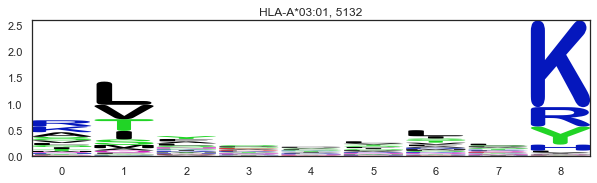

In [6]:
target_allele = ALLELES[0]
target_length = TARGET_LENGTHS[0]
peptides = per_allele_per_kfold_per_length_binders_train[target_allele][0][target_length]
make_logo_for_data(peptides, ALLELES[0])

# Prepare set of properties

In [7]:
from aaindex.aaindex import aaindex
IMPORTANT_PROPERTIES_FROM_PAPER = [
    "GEIM800103",
    "OOBM770104",
    "QIAN880132",
    "PALJ810115",
    "OOBM850102",
    "NADH010106",
    "RADA880106",
    "QIAN880112",
    "WEBA780101",
    "QIAN880125",
    "JOND750101",
    "QIAN880124"
]
IMPORTANT_AFTER_RANDOM_FOREST = [
    'KARS160116',
    'ARGP820102',
    'EISD860103',
    'OOBM850103',
    'WOLS870102',
    'FAUJ880106',
    'HUTJ700102',
    'LEVM760105',
    'FAUJ880103',
    'KARS160115',
    'MITS020101',
    'RADA880103',
    'SNEP660103',
    'CHOC760101',
    'CHOC760102',
    'KARS160107',
    'KARS160106',
    'CHOC760103',
    'CHAM820101'
]

MIX_OF_FEATURES = [
    "GEIM800103",
    "OOBM770104",
    "QIAN880132",
    "PALJ810115",
    "OOBM850102",
    "NADH010106",
    "RADA880106",
    "QIAN880112",
    'ARGP820102',
    "WEBA780101",
    "QIAN880125",
    "JOND750101",
    "QIAN880124"
]
all_properties = list(aaindex.get_all_categories().keys())

selected_properties = all_properties
properties_num = len(selected_properties)
record_values = aaindex[selected_properties[0]]['values']
transform_dicts = list()
for i in range (properties_num):
    transform_dicts.append(aaindex[selected_properties[i]]['values'])


In [12]:
aaindex['WOLS870102']

{'category': 'meta',
 'description': 'Principal property value z2 (Wold et al., 1987)',
 'notes': '',
 'refs': "Wold, S., Eriksson, L., Hellberg, S., Jonsson, J., Sjostrom, M., Skagerberg, B. and Wikstrom, C. 'Principal property values for six non-natural amino acids and their application to a structure-activity relationship for oxytocin peptide analogues' Can. J. Chem. 65, 1814-1820 (1987); Kawashima, S. and Kanehisa, M.                     'AAindex: amino acid index database.'  Nucleic Acids Res. 28, 374 (2000).",
 'values': {'-': 0,
  'A': -1.73,
  'C': -0.97,
  'D': 1.13,
  'E': 0.39,
  'F': 1.3,
  'G': -5.36,
  'H': 1.74,
  'I': -1.68,
  'K': 1.41,
  'L': -1.03,
  'M': -0.27,
  'N': 1.45,
  'P': 0.88,
  'Q': 0.53,
  'R': 2.52,
  'S': -1.63,
  'T': -2.09,
  'V': -2.53,
  'W': 3.65,
  'Y': 2.32}}

In [549]:
selected_properties

['ANDN920101',
 'ARGP820101',
 'ARGP820102',
 'ARGP820103',
 'AURR980101',
 'AURR980102',
 'AURR980103',
 'AURR980104',
 'AURR980105',
 'AURR980106',
 'AURR980107',
 'AURR980108',
 'AURR980109',
 'AURR980110',
 'AURR980111',
 'AURR980112',
 'AURR980113',
 'AURR980114',
 'AURR980115',
 'AURR980116',
 'AURR980117',
 'AURR980118',
 'AURR980119',
 'AURR980120',
 'AVBF000101',
 'AVBF000102',
 'AVBF000103',
 'AVBF000104',
 'AVBF000105',
 'AVBF000106',
 'AVBF000107',
 'AVBF000108',
 'AVBF000109',
 'BAEK050101',
 'BASU050101',
 'BASU050102',
 'BASU050103',
 'BEGF750101',
 'BEGF750102',
 'BEGF750103',
 'BHAR880101',
 'BIGC670101',
 'BIOV880101',
 'BIOV880102',
 'BLAM930101',
 'BLAS910101',
 'BROC820101',
 'BROC820102',
 'BULH740101',
 'BULH740102',
 'BUNA790101',
 'BUNA790102',
 'BUNA790103',
 'BURA740101',
 'BURA740102',
 'CASG920101',
 'CEDJ970101',
 'CEDJ970102',
 'CEDJ970103',
 'CEDJ970104',
 'CEDJ970105',
 'CHAM810101',
 'CHAM820101',
 'CHAM820102',
 'CHAM830101',
 'CHAM830102',
 'CHAM8301

# Transform data

In [550]:
from data_reading_methods import merge_per_allele_sets_into_combination_sets

per_allele_per_kfold_per_length_binders_train_old = per_allele_per_kfold_per_length_binders_train
per_allele_per_kfold_per_length_binders_test_old = per_allele_per_kfold_per_length_binders_test


if check_peptides:
    transform_dicts=None

per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test = merge_per_allele_sets_into_combination_sets(
    per_allele_per_kfold_per_length_binders_train, per_allele_per_kfold_per_length_binders_test,
    combination_size=combination_size,
    selected_alelles=ALLELES,
    total_splits=TOTAL_SPLITS,
    list_of_transform_dicts=transform_dicts
)
OLD_ALLELES = ALLELES
NEW_ALLELES = list(per_allele_per_kfold_per_length_binders_test.keys())
ALLELES = NEW_ALLELES

HLA-A*03:01
Length 8: HLA-A*03:01 - 93 
Length 9: HLA-A*03:01 - 5132 
Length 10: HLA-A*03:01 - 2184 
Length 11: HLA-A*03:01 - 691 
Length 12: HLA-A*03:01 - 202 
Length 13: HLA-A*03:01 - 98 
Length 14: HLA-A*03:01 - 31 
Length 15: HLA-A*03:01 - 18 
Length 16: HLA-A*03:01 - 12 
Length 17: HLA-A*03:01 - 5 
Length 18: HLA-A*03:01 - 4 


## Check feature importance

In [551]:
peptides = per_allele_per_kfold_per_length_binders_train[ALLELES[0]][0][9]

In [552]:
peptides[1]

array([[ 4.38,  0.6 ,  0.2 , ..., 52.  , 10.76,  4.6 ],
       [ 3.95,  1.32,  1.08, ...,  0.13,  5.96, 14.3 ],
       [ 4.6 ,  1.88,  0.39, ...,  1.61,  5.66, 15.  ],
       ...,
       [ 3.95,  2.22,  1.45, ...,  0.13,  6.02, 17.1 ],
       [ 4.38,  0.6 ,  0.2 , ..., 52.  , 10.76,  4.6 ],
       [ 4.38,  0.6 ,  0.2 , ..., 52.  , 10.76,  4.6 ]])

In [553]:
peptides[0][1]

array([ 4.3500e+00,  5.0000e-02,  8.4000e-01,  9.1000e-01,  8.7000e-01,
        8.0000e-01,  1.0300e+00,  1.1300e+00,  1.4100e+00,  7.7000e-01,
        9.2000e-01,  7.5000e-01,  6.5000e-01,  7.0000e-01,  7.3000e-01,
        7.9000e-01,  4.6000e-01,  5.7000e-01,  5.0000e-01,  8.2000e-01,
        8.2000e-01,  8.4000e-01,  7.9000e-01,  8.6000e-02,  4.1200e-01,
        3.0800e-01, -2.4000e-01, -6.2900e-01, -1.5200e-01, -9.3000e-02,
       -3.6700e-01, -2.3300e-01, -2.4300e-01, -7.0100e-02,  5.8900e-02,
        2.3900e-02,  1.4620e-01,  4.4000e-01,  8.3000e-01,  7.5000e-01,
        4.4400e-01,  7.1200e+01, -3.8000e+01, -5.4000e+01,  5.4000e-01,
        4.5000e-01,  8.0000e-01,  1.1000e+00, -5.2000e-01,  6.5500e-01,
        8.2360e+00,  4.3460e+00,  6.9000e+00,  2.7200e-01,  3.8800e-01,
       -4.0000e-01,  6.0000e+00,  6.1000e+00,  5.6000e+00,  5.3000e+00,
        5.1000e+00,  5.0000e-01,  1.0800e-01,  0.0000e+00,  1.0800e+00,
        1.6600e-01,  2.0000e+00,  0.0000e+00,  0.0000e+00,  1.00

In [554]:
# make matrix of features and examples

In [578]:
selected_positions = [8, 4]
selected_data_for_position = list()
selected_data_for_position_y = list()
for peptide in peptides:
    for selected_position in selected_positions:
        selected_data_for_position.append(peptide[selected_position])
        selected_data_for_position_y.append(selected_position)

In [579]:
from sklearn.preprocessing import StandardScaler
X = np.array(selected_data_for_position)
y = np.array(selected_data_for_position_y)
scaler = StandardScaler()
X = scaler.fit_transform(X)
feature_names = selected_properties

In [580]:
from sklearn.utils import shuffle
X, y = shuffle(X, y, random_state=0)

In [581]:
from sklearn.decomposition import TruncatedSVD, PCA
import seaborn as sns
svd = TruncatedSVD(n_components=10)
pca = PCA(n_components=10)

algo_object = pca

In [582]:
algo_object.fit(X)

PCA(n_components=10)

In [583]:
df = pd.DataFrame({"component": np.arange(0, len(algo_object.explained_variance_ratio_)), "variance":algo_object.explained_variance_ratio_ })

In [584]:
df

,component,variance
0,0,0.334135
1,1,0.207338
2,2,0.133774
3,3,0.074184
4,4,0.057334
5,5,0.040560
6,6,0.032202
7,7,0.023221
8,8,0.018356
9,9,0.013955


Text(0.5, 1.0, 'Correlation of features')

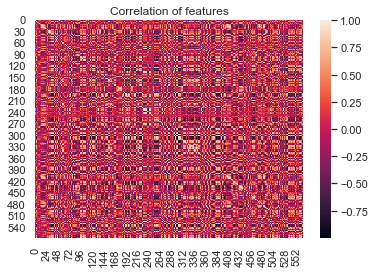

In [589]:
df = pd.DataFrame(X).corr()
ax = sns.heatmap(df)
ax.set_title("Correlation of features")


D:\Tools\Python\Anaconda\envs\pomegranate\lib\site-packages\seaborn\matrix.py:654: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


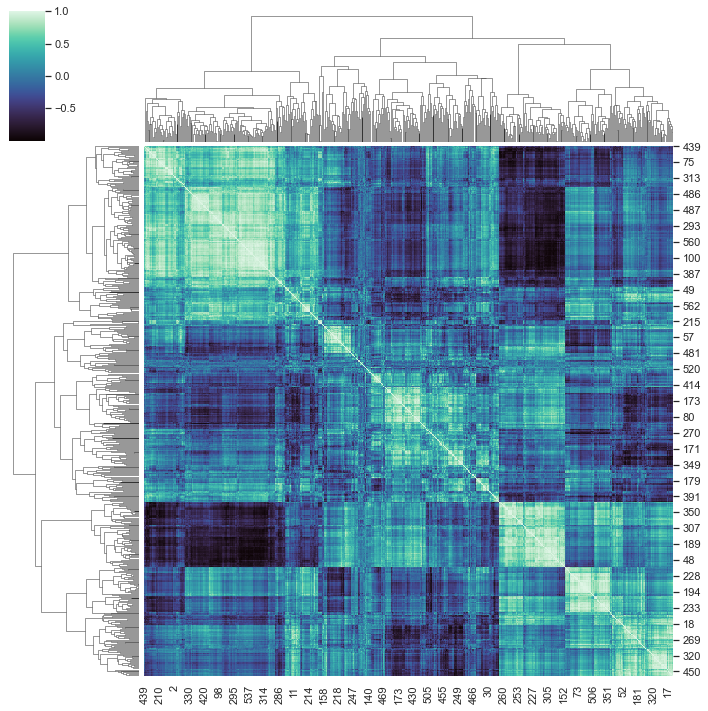

In [592]:
sns.clustermap(df, cmap='mako')

Text(0.5, 1.0, 'Explained variance for position [8, 4]')

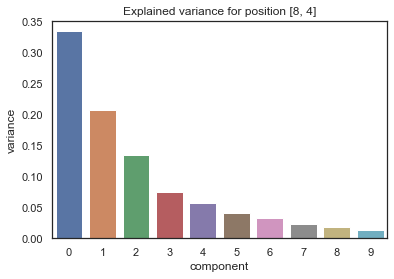

In [587]:
ax = sns.barplot(data=df, x ="component", y="variance")
ax.set_title(f"Explained variance for position {selected_positions}")

In [566]:
algo_object.explained_variance_ratio_

array([0.50825154, 0.17971538, 0.12024597, 0.08480731, 0.03694542,
       0.0171044 , 0.01313056, 0.00923236, 0.00647262, 0.00501672])

In [567]:
algo_object.singular_values_

array([1215.04088855,  722.51050828,  590.99907964,  496.3273316 ,
        327.59090696,  222.89761776,  195.29592144,  163.7600532 ,
        137.11706591,  120.71509062])

In [568]:
component_formula = list()
for i in range(len(algo_object.components_)):

    component_formula ="\n\t".join([
        "%+0.3f * %s" % (coef, feat)
        for coef, feat in zip(algo_object.components_[i], feature_names) if coef > 0.02 or coef < -0.02
    ])

    print(f"{i}: \t{component_formula}")



0: 	+0.040 * ANDN920101
	+0.031 * ARGP820101
	+0.029 * ARGP820102
	+0.038 * ARGP820103
	+0.034 * AURR980104
	-0.031 * AURR980106
	-0.039 * AURR980109
	-0.025 * AURR980110
	-0.053 * AURR980114
	-0.053 * AURR980115
	-0.045 * AURR980116
	-0.029 * AURR980117
	-0.023 * AURR980118
	-0.048 * AURR980119
	-0.045 * AURR980120
	+0.045 * AVBF000101
	+0.048 * AVBF000103
	+0.032 * AVBF000104
	+0.050 * AVBF000105
	+0.051 * AVBF000106
	+0.035 * AVBF000107
	+0.050 * AVBF000108
	+0.055 * AVBF000109
	+0.058 * BAEK050101
	+0.056 * BASU050101
	+0.057 * BASU050102
	+0.056 * BASU050103
	-0.027 * BEGF750101
	+0.055 * BEGF750102
	-0.028 * BHAR880101
	+0.021 * BIGC670101
	+0.056 * BIOV880101
	+0.054 * BIOV880102
	+0.043 * BLAS910101
	+0.049 * BROC820101
	+0.047 * BROC820102
	-0.051 * BULH740101
	-0.021 * BULH740102
	+0.049 * BUNA790102
	-0.049 * BURA740101
	+0.048 * BURA740102
	+0.057 * CASG920101
	-0.043 * CEDJ970101
	-0.042 * CEDJ970102
	-0.049 * CEDJ970104
	-0.051 * CEDJ970105
	+0.037 * CHAM820101
	+0.048 * 

In [569]:
best_fearures = [feature_names[i] for i in algo_object.components_[0].argsort()[::-1]]
best_fearures

['MAXF760102',
 'LIFS790103',
 'ROBB790101',
 'ISOY800102',
 'ZHOH040103',
 'BAEK050101',
 'QIAN880121',
 'LIFS790101',
 'QIAN880120',
 'QIAN880122',
 'FASG760102',
 'CHOP780202',
 'LEVM780102',
 'PRAM900103',
 'CORJ870106',
 'SUYM030101',
 'CASG920101',
 'PONP800108',
 'ZIMJ680105',
 'ZHOH040101',
 'BASU050102',
 'ZHOH040102',
 'NISK800101',
 'PONP800102',
 'NADH010103',
 'NADH010104',
 'LEVM780105',
 'NADH010102',
 'PONP800101',
 'PONP800103',
 'CIDH920101',
 'PONP930101',
 'WIMW960101',
 'CHOP780209',
 'SNEP660104',
 'MIYS850101',
 'NISK860101',
 'KANM800102',
 'PALJ810103',
 'BIOV880101',
 'BASU050101',
 'NOZY710101',
 'CIDH920103',
 'BASU050103',
 'GEIM800107',
 'CORJ870107',
 'FODM020101',
 'CIDH920102',
 'CIDH920105',
 'CORJ870105',
 'PALJ810111',
 'DESM900101',
 'MEEJ810101',
 'QIAN880127',
 'NAKH900110',
 'ROSG850102',
 'FAUJ830101',
 'ROBB760105',
 'TANS770103',
 'CORJ870101',
 'MEEJ810102',
 'PALJ810112',
 'AVBF000109',
 'PALJ810104',
 'BEGF750102',
 'CORJ870102',
 'SWER8301

In [570]:
selected_component = 0
important_features_df = pd.DataFrame([item for item in  zip(feature_names, algo_object.components_[selected_component])], columns=["name", "coef"]).sort_values(by='coef', ascending=False).reset_index(drop=True)
important_features_df.head(50)

,name,coef
0,MAXF760102,0.058190
1,LIFS790103,0.058172
2,ROBB790101,0.057937
3,ISOY800102,0.057852
4,ZHOH040103,0.057773
5,BAEK050101,0.057641
6,QIAN880121,0.057598
7,LIFS790101,0.057464
8,QIAN880120,0.057340
9,QIAN880122,0.057176


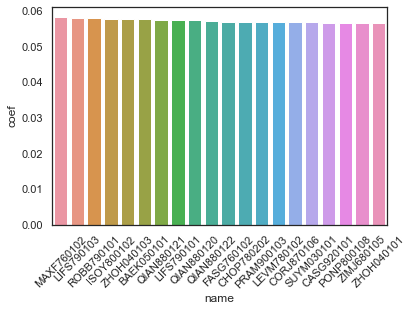

In [571]:
ax = sns.barplot(data=important_features_df[:20], x='name', y='coef')
for item in ax.get_xticklabels():
    item.set_rotation(45)

In [572]:
top_10_best = important_features_df[:20].name.values

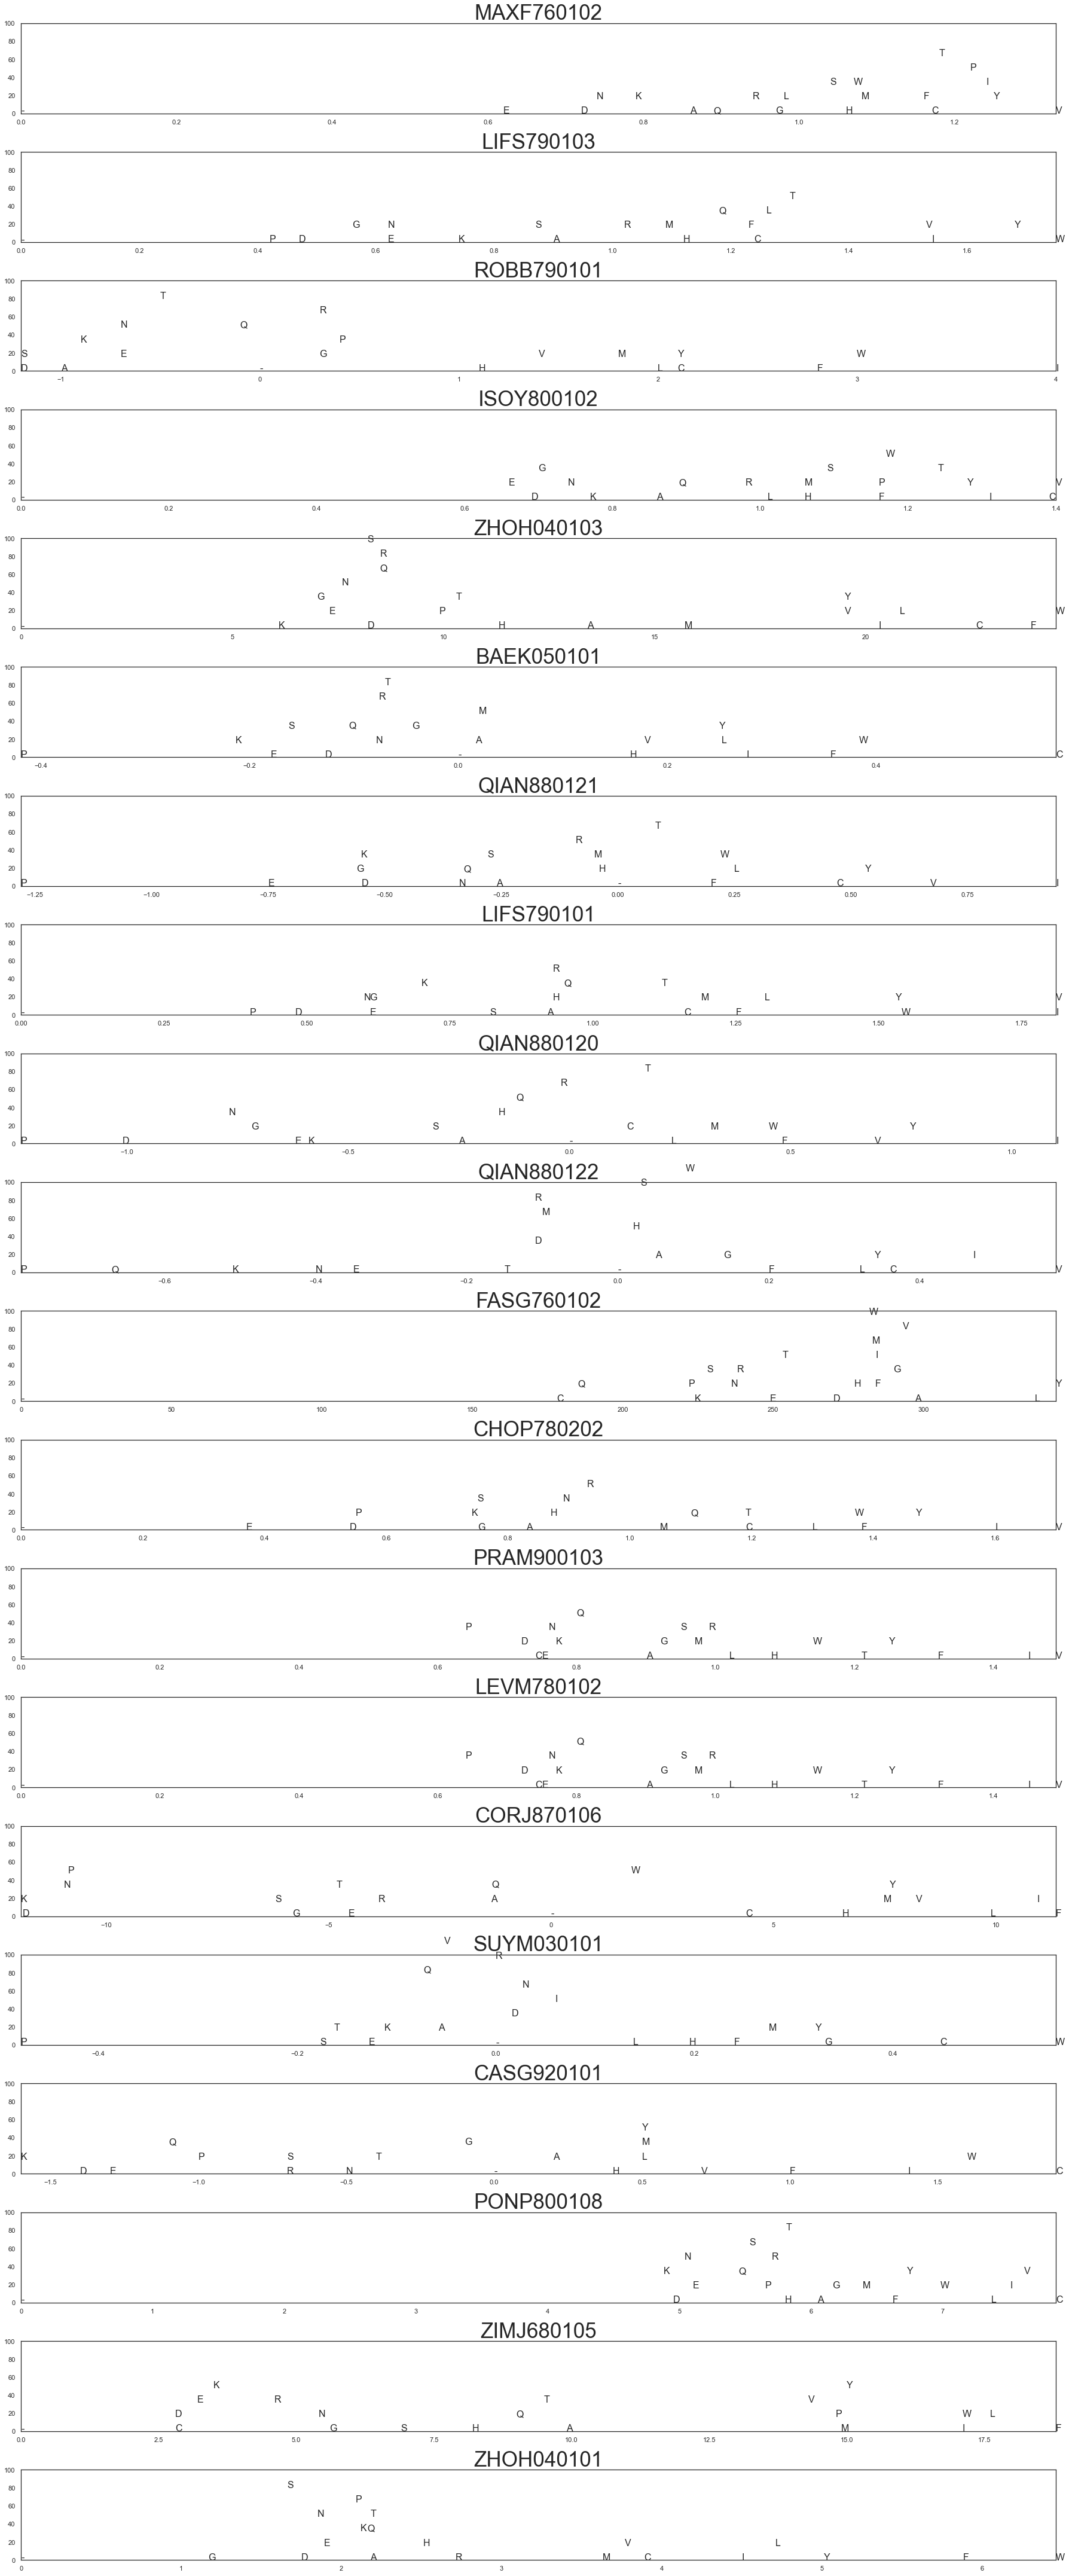

In [573]:
from collections import defaultdict
import matplotlib.pyplot as plt
fig, axes = plt.subplots(ncols=1, nrows=len(top_10_best), figsize=(25, len(top_10_best)* 3))
for i, prop_id in enumerate(top_10_best):
    ax = axes[i]
    transform_dict = aaindex[prop_id]['values']
    x_left = min(transform_dict.values())
    x_right = max(transform_dict.values())
    std_value = np.std(list(transform_dict.values()))
    ax.set_xlim(x_left, x_right)
    ax.set_ylim(0, 100)

    # x = np.linspace(x_left, x_right, 1000)
    # y1= [1 for item in x]
    # axes[i].plot(x, y1, 'r', lw=2, label=f'result')

    scale_value_y = 16
    scale_value_x = std_value/3
    aa_to_x_position = dict()
    x_position_bin_to_aa = defaultdict(list)
    for aa,prop_value in transform_dict.items():
        aa_to_x_position[aa] = prop_value
    aa_to_y_position = dict()
    for aa,x_pos in aa_to_x_position.items():
        x_position_bin_to_aa[int(x_pos/scale_value_x)].append(aa)
    for bin, aas in x_position_bin_to_aa.items():
        for j, aa in enumerate(aas):
            aa_to_y_position[aa] = scale_value_y*j
    for aa,prop_value in transform_dict.items():
        ax.text(aa_to_x_position[aa], aa_to_y_position[aa], aa, fontsize=16 )

    ax.set_title(prop_id, fontsize=35)
plt.tight_layout()

In [574]:
transformed_X = algo_object.transform(X)

In [489]:
transformed_X

array([[ 9.36844161e-01, -1.26865926e+00,  2.93693583e-01, ...,
         9.75086425e-04, -4.67708494e-03, -2.15194953e-03],
       [-4.50381609e+00,  3.42535471e+00,  1.77629432e+00, ...,
        -2.56572747e-02, -1.77513945e-02,  3.85513019e-03],
       [ 9.36844161e-01, -1.26865926e+00,  2.93693583e-01, ...,
         9.75086425e-04, -4.67708494e-03, -2.15194953e-03],
       ...,
       [ 9.36844161e-01, -1.26865926e+00,  2.93693583e-01, ...,
         9.75086425e-04, -4.67708494e-03, -2.15194953e-03],
       [ 9.36844161e-01, -1.26865926e+00,  2.93693583e-01, ...,
         9.75086425e-04, -4.67708494e-03, -2.15194953e-03],
       [ 9.36844161e-01, -1.26865926e+00,  2.93693583e-01, ...,
         9.75086425e-04, -4.67708494e-03, -2.15194953e-03]])

In [490]:
transformed_X[0]

array([ 9.36844161e-01, -1.26865926e+00,  2.93693583e-01, -6.42300863e-02,
       -1.05176321e-01,  7.18091120e-02,  2.68782760e-03,  9.75086425e-04,
       -4.67708494e-03, -2.15194953e-03])

In [491]:
df = pd.DataFrame({"pc0": transformed_X[:, 0],"pc1": transformed_X[:, 1], "y": [str(value) for value in y] })

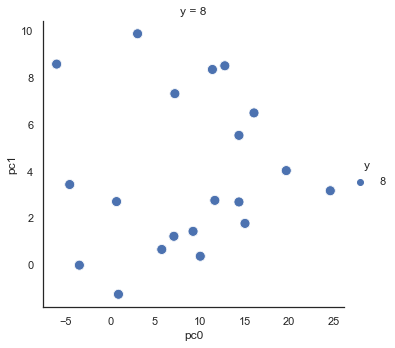

In [492]:
sns.relplot(data=df, x="pc0", y="pc1", hue='y', col='y', s=100)

In [382]:
df.y.value_counts()

8    5132
4    5132
Name: y, dtype: int64

In [383]:
df

,pc0,pc1,y
0,-12.688951,-6.321361,8
1,-9.026648,-1.826762,4
2,-6.959976,-5.860330,8
3,15.747731,-0.980503,4
4,-12.688951,-6.321361,8
...,...,...,...
10259,-6.959976,-5.860330,4
10260,-2.369090,15.818880,4
10261,-12.688951,-6.321361,8
10262,27.942687,-5.335324,4


In [263]:
df['pc0'].unique()

array([-12.68895132,  -9.0266479 ,  -6.95997638,  15.74773148,
        27.94268699,  25.44988623,   5.10382495,  -1.96914379,
        18.50580984,  24.53739707,  -1.93309584,  -4.54057342,
         6.19065128,   3.34535154,  23.06192704,  -7.17869591,
        -2.36909005,  -9.76129774,  20.84372321,  16.51295925])

Text(0.5, 1.0, 'Component coefficients for position 8')

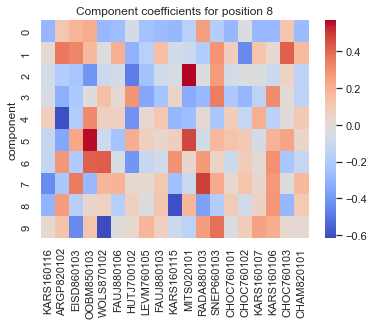

In [493]:
df = pd.DataFrame(algo_object.components_, columns =feature_names)
df.index.name = "component"
ax = sns.heatmap(df, cmap='coolwarm',)
ax.set_title(f"Component coefficients for position {selected_position}")

In [265]:
df

,ANDN920101,ARGP820101,ARGP820102,ARGP820103,AURR980101,AURR980102,AURR980103,AURR980104,AURR980105,AURR980106,...,YUTK870104,ZASB820101,ZHOH040101,ZHOH040102,ZHOH040103,ZIMJ680101,ZIMJ680102,ZIMJ680103,ZIMJ680104,ZIMJ680105
component,,,,,,,,,,,,,,,,,,,,,
0,-0.010913,0.033003,0.055010,0.058807,-0.015177,-0.029655,-0.011460,0.006942,-0.010272,-0.021329,...,0.013357,0.013014,0.060427,0.053281,0.070499,0.033229,0.038426,-0.055912,-0.048804,0.066708
1,0.002139,-0.020752,0.002656,-0.000679,0.001027,0.035654,0.030152,0.069493,0.057382,0.006896,...,0.016692,-0.051242,-0.031991,-0.042080,-0.009710,-0.016962,-0.043078,-0.046459,-0.045091,0.014666
2,-0.073673,-0.039697,0.040342,0.035594,-0.037937,-0.052698,0.002511,-0.012277,-0.005836,-0.029351,...,0.040087,-0.048577,-0.038342,-0.046320,-0.014791,-0.035151,-0.025004,-0.012742,-0.011734,-0.017064
3,-0.022585,0.092710,0.032266,0.027929,0.029284,0.012326,-0.018402,-0.009935,-0.013943,0.100007,...,0.038077,-0.001120,0.008068,0.021601,0.005562,0.087289,0.090712,0.001948,0.014615,0.040477
4,-0.017908,-0.070560,0.024312,0.026940,0.023541,-0.017301,-0.047729,0.055111,0.000155,0.028072,...,-0.130657,-0.066716,-0.023214,-0.003164,-0.009296,-0.068237,-0.010060,0.018399,0.017323,-0.009453
5,0.112920,-0.036467,0.015672,0.004041,-0.020594,-0.052330,0.114627,0.058789,0.066687,0.036485,...,0.078148,-0.022600,-0.014775,-0.004107,0.002906,-0.046387,-0.013274,0.005466,-0.077693,0.000438
6,-0.007321,-0.025548,-0.043551,-0.054322,-0.131807,-0.094135,-0.085631,-0.033706,0.062890,-0.039761,...,0.045696,-0.018370,-0.026347,-0.013474,-0.015259,-0.007426,0.050508,-0.014012,-0.008241,-0.017525
7,-0.071157,0.009878,-0.043646,-0.043266,0.061836,0.018855,0.053243,-0.069260,-0.080548,-0.064291,...,-0.005042,0.089068,-0.037348,-0.037125,-0.021861,-0.012445,-0.011401,0.055520,0.082216,-0.020758
8,-0.065314,0.028405,-0.107050,-0.081356,0.127842,0.042414,-0.021641,-0.041613,-0.049808,0.131813,...,0.020012,-0.083749,-0.010078,-0.026914,0.002032,0.010148,-0.004171,0.010815,-0.062944,-0.020666


## Feature importance

In [398]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

In [399]:
y[y==8] = 1
y[y==4] = 0

In [400]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

In [401]:
len(feature_names)

566

In [402]:
forest = RandomForestClassifier(random_state=0)
forest.fit(X_train, y_train)

RandomForestClassifier(random_state=0)

In [403]:
import time
import numpy as np
start_time = time.time()
importances = forest.feature_importances_
std = np.std([tree.feature_importances_ for tree in forest.estimators_], axis=0)
elapsed_time = time.time() - start_time

print(f"Elapsed time to compute the importances: {elapsed_time:.3f} seconds")

Elapsed time to compute the importances: 0.024 seconds


In [404]:
std

array([3.07456461e-05, 1.37304407e-02, 1.98169492e-01, 2.77897081e-03,
       5.06654449e-05, 2.76492475e-03, 6.94470281e-03, 2.65113402e-03,
       3.77208238e-03, 2.05350649e-06, 1.13422233e-02, 1.06126896e-06,
       8.82055586e-04, 1.21608226e-02, 1.21111990e-02, 3.56275006e-07,
       4.09122966e-04, 5.85238619e-04, 1.30483313e-04, 4.75896834e-03,
       2.80647240e-06, 7.57973313e-03, 2.26095358e-02, 0.00000000e+00,
       5.29886862e-06, 4.64904524e-05, 2.97147971e-03, 1.05406356e-04,
       2.57301981e-05, 1.84893659e-07, 3.50119721e-03, 6.10659119e-05,
       1.91860491e-03, 2.29194243e-05, 7.60210553e-06, 8.24037575e-09,
       1.85729989e-06, 5.57433020e-03, 5.66956486e-04, 3.61129995e-03,
       5.00115186e-06, 7.66660659e-02, 8.53807780e-03, 2.06396448e-07,
       1.38745445e-04, 2.70583580e-07, 1.11181278e-05, 4.70205198e-04,
       1.63430799e-06, 9.34614482e-05, 2.23282787e-04, 1.87873825e-05,
       2.60109737e-06, 8.26710666e-05, 5.83261376e-03, 5.88104971e-09,
      

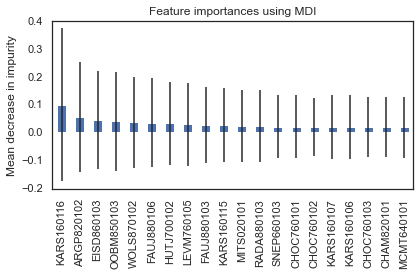

In [405]:
import pandas as pd

forest_importances = pd.Series(importances, index=feature_names)
df = pd.DataFrame({"importances": importances, "std": std}, index=feature_names)
fig, ax = plt.subplots()

df = df.sort_values(by='importances', ascending=False)[:20]
df['importances'].plot.bar(yerr=df['std'], ax=ax)

# forest_importances.sort_values(ascending=False)[:20].plot.bar(yerr=std, ax=ax)
ax.set_title("Feature importances using MDI")
ax.set_ylabel("Mean decrease in impurity")
fig.tight_layout()

In [406]:
df

,importances,std
KARS160116,0.096981,0.275834
ARGP820102,0.054463,0.198169
EISD860103,0.041836,0.176428
OOBM850103,0.036911,0.178993
WOLS870102,0.033613,0.162984
FAUJ880106,0.033024,0.161789
HUTJ700102,0.030154,0.150702
LEVM760105,0.026207,0.149017
FAUJ880103,0.024369,0.138524
KARS160115,0.023639,0.134418


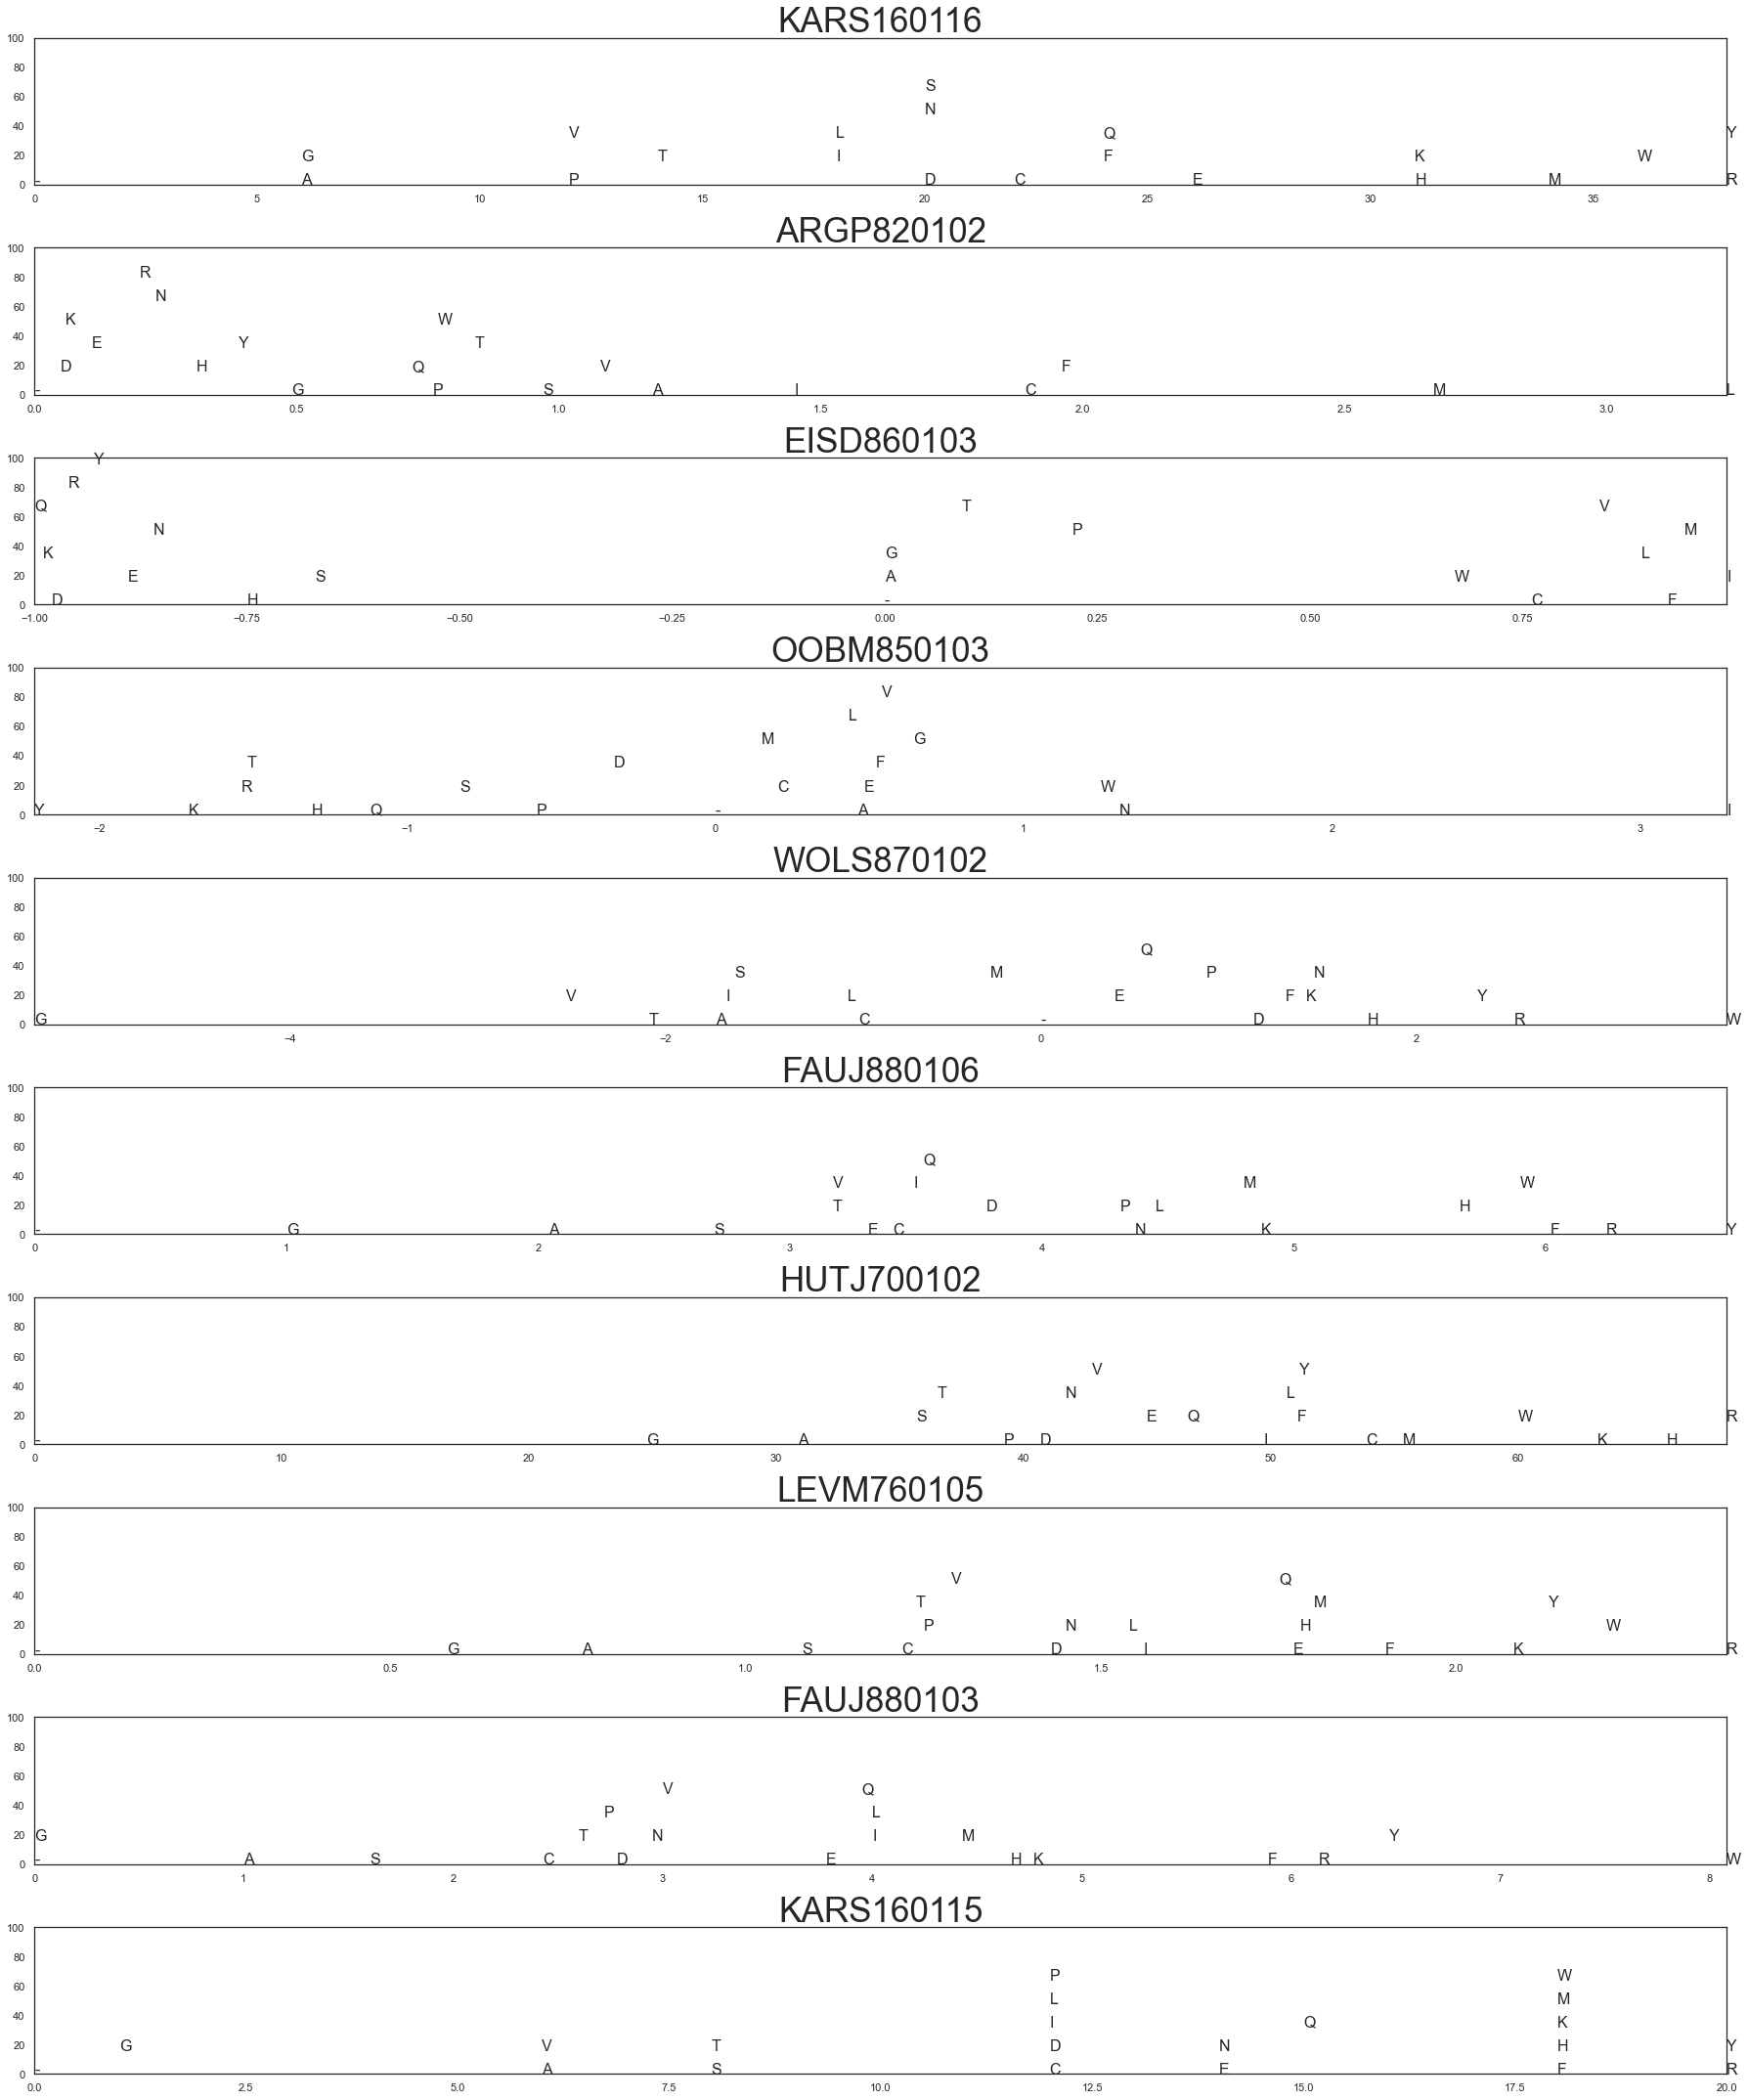

In [408]:
top_10_best = df[:10].index.values
from collections import defaultdict
import matplotlib.pyplot as plt
fig, axes = plt.subplots(ncols=1, nrows=len(top_10_best), figsize=(25, len(top_10_best)* 3))
for i, prop_id in enumerate(top_10_best):
    ax = axes[i]
    transform_dict = aaindex[prop_id]['values']
    x_left = min(transform_dict.values())
    x_right = max(transform_dict.values())
    std_value = np.std(list(transform_dict.values()))
    ax.set_xlim(x_left, x_right)
    ax.set_ylim(0, 100)

    # x = np.linspace(x_left, x_right, 1000)
    # y1= [1 for item in x]
    # axes[i].plot(x, y1, 'r', lw=2, label=f'result')

    scale_value_y = 16
    scale_value_x = std_value/3
    aa_to_x_position = dict()
    x_position_bin_to_aa = defaultdict(list)
    for aa,prop_value in transform_dict.items():
        aa_to_x_position[aa] = prop_value
    aa_to_y_position = dict()
    for aa,x_pos in aa_to_x_position.items():
        x_position_bin_to_aa[int(x_pos/scale_value_x)].append(aa)
    for bin, aas in x_position_bin_to_aa.items():
        for j, aa in enumerate(aas):
            aa_to_y_position[aa] = scale_value_y*j
    for aa,prop_value in transform_dict.items():
        ax.text(aa_to_x_position[aa], aa_to_y_position[aa], aa, fontsize=16 )

    ax.set_title(prop_id, fontsize=35)
plt.tight_layout()

# Permutation importance

In [288]:
from sklearn.inspection import permutation_importance

In [289]:
result = permutation_importance(
    forest, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
)

In [290]:
forest_importances = pd.Series(result.importances_mean, index=feature_names)

<AxesSubplot:>

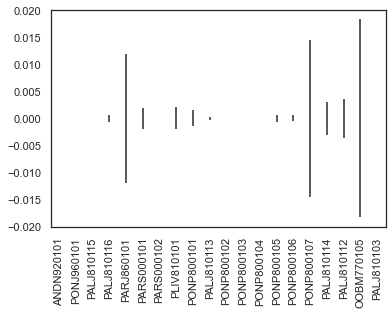

In [291]:
df = pd.DataFrame({"importances": result.importances_mean, "std": std}, index=feature_names)
fig, ax = plt.subplots()

df = df.sort_values(by='importances', ascending=False)[:20]
df['importances'].plot.bar(yerr=df['std'], ax=ax)

In [293]:
result

{'importances_mean': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 